# L8 데이터 분석 실습


In [1]:
import pandas as pd
df = pd.read_csv("sales_data.csv")
df.shape


(1030, 14)

In [2]:
df.head()

,order_date,shipping_date,delivery_date,region,category,product_id,quantity,unit_price,customer_id,customer_age,customer_gender,satisfaction,status,total_sales
0,2023-01-01,2023-01-04,2023-01-03,부산,전자제품,2772,61,34977.69,327,67.0,M,1.0,배송중,2133639.09
1,2023-01-02,2023-01-06,2023-01-04,부산,식품,3780,64,312589.27,318,34.0,M,4.0,배송완료,20005713.28
2,2023-01-03,2023-01-04,2023-01-05,부산,의류,8423,5,111813.88,297,50.0,F,4.0,배송완료,559069.40
3,2023-01-04,2023-01-07,2023-01-10,대구,식품,3871,53,297971.54,479,61.0,M,5.0,배송완료,15792491.62
4,2023-01-05,2023-01-08,2023-01-10,서울,식품,1660,55,65058.60,499,60.0,F,2.0,배송중,3578223.00


## 1차시: 데이터 로딩과 구조 (L8-1 7~14쪽)


In [3]:
import sys
import hashlib
from pathlib import Path
from IPython.display import display, Markdown

source_file = Path('sales_data.csv')
source_sha256 = hashlib.sha256(source_file.read_bytes()).hexdigest()
print('커널:', sys.executable)
print('pandas:', pd.__version__)
print('원본 크기:', df.shape)
assert df.shape == (1030, 14)
raw = df.copy(deep=True)
df.iloc[0]

커널: C:\Users\seho1\Desktop\대학자료\웹기반시스템\flask-practice1\data_analysis\.venv\Scripts\python.exe
pandas: 3.1.0
원본 크기: (1030, 14)


order_date         2023-01-01
shipping_date      2023-01-04
delivery_date      2023-01-03
region                     부산
category                 전자제품
product_id               2772
quantity                   61
unit_price           34977.69
customer_id               327
customer_age             67.0
customer_gender             M
satisfaction              1.0
status                    배송중
total_sales        2133639.09
Name: 0, dtype: object

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   order_date       1030 non-null   str    
 1   shipping_date    1030 non-null   str    
 2   delivery_date    1025 non-null   str    
 3   region           1030 non-null   str    
 4   category         1030 non-null   str    
 5   product_id       1030 non-null   int64  
 6   quantity         1030 non-null   int64  
 7   unit_price       1030 non-null   float64
 8   customer_id      1030 non-null   int64  
 9   customer_age     979 non-null    float64
 10  customer_gender  1030 non-null   str    
 11  satisfaction     1000 non-null   float64
 12  status           1030 non-null   str    
 13  total_sales      1030 non-null   float64
dtypes: float64(4), int64(3), str(7)
memory usage: 112.8 KB


In [5]:
df.describe()

,product_id,quantity,unit_price,customer_id,customer_age,satisfaction,total_sales
count,1030.000000,1030.000000,1030.000000,1030.000000,979.000000,1000.000000,1.030000e+03
mean,5365.692233,65.134951,248893.777214,240.780583,44.858018,2.956000,1.235946e+07
std,2557.264515,113.597931,139497.370968,147.105954,14.253807,1.458146,1.065892e+07
min,1002.000000,1.000000,10455.410000,1.000000,20.000000,1.000000,2.376040e+04
25%,3292.500000,25.000000,129378.125000,107.000000,32.000000,2.000000,3.456833e+06
50%,5191.500000,50.000000,247732.410000,234.500000,45.000000,3.000000,9.425458e+06
75%,7581.250000,75.000000,369780.650000,368.750000,57.000000,4.000000,1.920825e+07
max,9996.000000,990.000000,498783.880000,499.000000,69.000000,5.000000,4.688031e+07


## 실습 2: 데이터 품질 점검 (L8-1 15~20쪽)


In [6]:
missing_before = df.isnull().sum()
display(missing_before)
display((missing_before / len(df) * 100).round(1).rename('결측 비율(%)'))

order_date          0
shipping_date       0
delivery_date       5
region              0
category            0
product_id          0
quantity            0
unit_price          0
customer_id         0
customer_age       51
customer_gender     0
satisfaction       30
status              0
total_sales         0
dtype: int64

order_date         0.0
shipping_date      0.0
delivery_date      0.5
region             0.0
category           0.0
product_id         0.0
quantity           0.0
unit_price         0.0
customer_id        0.0
customer_age       5.0
customer_gender    0.0
satisfaction       2.9
status             0.0
total_sales        0.0
Name: 결측 비율(%), dtype: float64

In [7]:
duplicates_before = int(df.duplicated().sum())
print('완전히 같은 중복 행:', duplicates_before)
df[df.duplicated(keep=False)].sort_values('order_date').head(4)

완전히 같은 중복 행: 26


,order_date,shipping_date,delivery_date,region,category,product_id,quantity,unit_price,customer_id,customer_age,customer_gender,satisfaction,status,total_sales
63,2023-03-05,2023-03-06,2023-03-08,광주,도서,4811,17,171974.89,324,58.0,M,3.0,배송완료,2923573.13
1029,2023-03-05,2023-03-06,2023-03-08,광주,도서,4811,17,171974.89,324,58.0,M,3.0,배송완료,2923573.13
1001,2023-05-09,2023-05-13,2023-05-15,서울,전자제품,7871,58,405781.73,259,61.0,F,5.0,배송중,23535340.34
128,2023-05-09,2023-05-13,2023-05-15,서울,전자제품,7871,58,405781.73,259,61.0,F,5.0,배송중,23535340.34


In [8]:
calc = df['quantity'] * df['unit_price']
diff = (df['total_sales'] - calc).abs()
mismatch_before = int((diff > 1).sum())
print('금액과 수량 × 단가의 차이가 1원 초과:', mismatch_before)
cols = ['quantity', 'unit_price', 'total_sales']
df.loc[diff > 1, cols].head(3)

금액과 수량 × 단가의 차이가 1원 초과: 22


,quantity,unit_price,total_sales
31,528,235225.85,22346455.75
188,943,303984.25,19151007.75
273,656,242263.07,18654256.39


In [9]:
dates = ['order_date', 'shipping_date', 'delivery_date']
for col in dates:
    df[col] = pd.to_datetime(df[col])
display(df[dates].agg(['min', 'max']))
today = pd.Timestamp.today()
late = df['shipping_date'] < df['order_date']
rev = df['delivery_date'] < df['shipping_date']
reversed_before = int(rev.sum())
print('미래 주문일:', (df['order_date'] > today).sum())
print('배송일 < 주문일:', late.sum())
print('도착일 < 배송일:', reversed_before)
print('수량 > 500:', (df['quantity'] > 500).sum())

,order_date,shipping_date,delivery_date
min,2023-01-01,2023-01-04,2023-01-03
max,2025-09-26,2025-09-29,2026-09-14


미래 주문일: 0
배송일 < 주문일: 0
도착일 < 배송일: 149
수량 > 500: 22


### 1차시 품질 점검 결과

|점검|결과|다음 단계|
|---|---|---|
|결측|나이 51, 만족도 30, 도착일 5|대체의 영향을 비교한 뒤 결정|
|중복 행|26|뒤쪽 중복 제거|
|금액 ≠ 수량 × 단가 (1원 초과)|22|어느 칸이 틀렸는지 확인|
|수량 최대|990|통계·업무 규칙과 비교|
|도착일 < 배송일|149|근거 없이 날짜를 바꾸지 않음|



## 2차시: 고치기 전에 그리기 (L8-1 23~25쪽 / L8-2 4~7쪽)


In [10]:
import matplotlib.pyplot as plt
import platform

fonts = {'Windows': 'Malgun Gothic', 'Darwin': 'AppleGothic'}
name = fonts.get(platform.system(), 'NanumGothic')
plt.rcParams['font.family'] = name
plt.rcParams['axes.unicode_minus'] = False

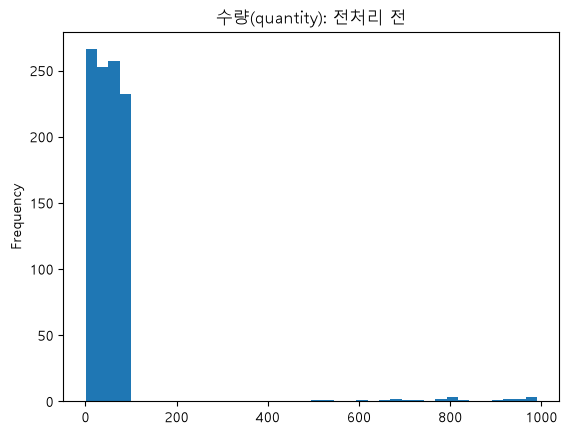

In [11]:
df['quantity'].plot.hist(bins=40, title='수량(quantity): 전처리 전')
plt.show()

Q1 = 25.0  Q3 = 75.0  IQR = 50.0
이상치 판정 상한 = 150.0
상한 이내 실제 수염 끝 = 99
상한 밖 건수 = 22


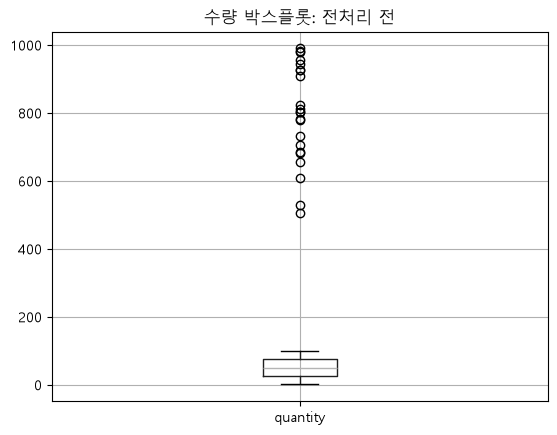

In [12]:
Q1 = df['quantity'].quantile(0.25)
Q3 = df['quantity'].quantile(0.75)
IQR = Q3 - Q1
upper = Q3 + 1.5 * IQR
print('Q1 =', Q1, ' Q3 =', Q3, ' IQR =', IQR)
print('이상치 판정 상한 =', upper)
print('상한 이내 실제 수염 끝 =', df.loc[df['quantity'] <= upper, 'quantity'].max())
print('상한 밖 건수 =', (df['quantity'] > upper).sum())
df.boxplot(column='quantity')
plt.title('수량 박스플롯: 전처리 전')
plt.show()

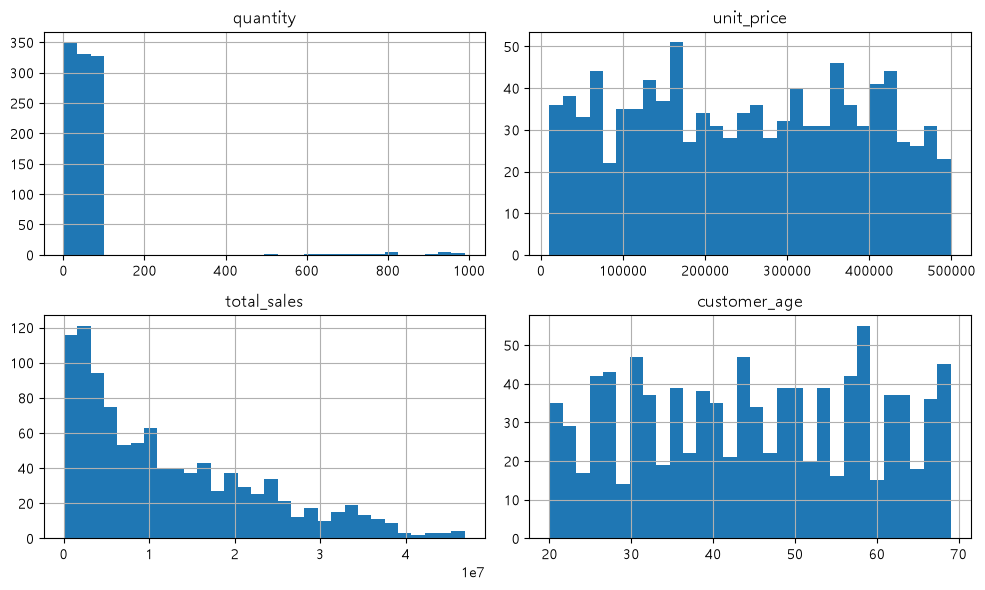

In [13]:
cols = ['quantity', 'unit_price', 'total_sales', 'customer_age']
df[cols].hist(bins=30, figsize=(10, 6))
plt.tight_layout()
plt.show()

## 실습 4: 결측 처리 비교 (L8-1 26~28쪽 / L8-2 8~10쪽)


In [14]:
dropped = df.dropna(subset=['customer_age'])
print('나이가 빈 행을 지우면:', len(df), '->', len(dropped))
print('이것은 비교용이며 df에는 적용하지 않습니다.')

나이가 빈 행을 지우면: 1030 -> 979
이것은 비교용이며 df에는 적용하지 않습니다.


평균: 44.858
중앙값: 44.858
최빈값: 44.858


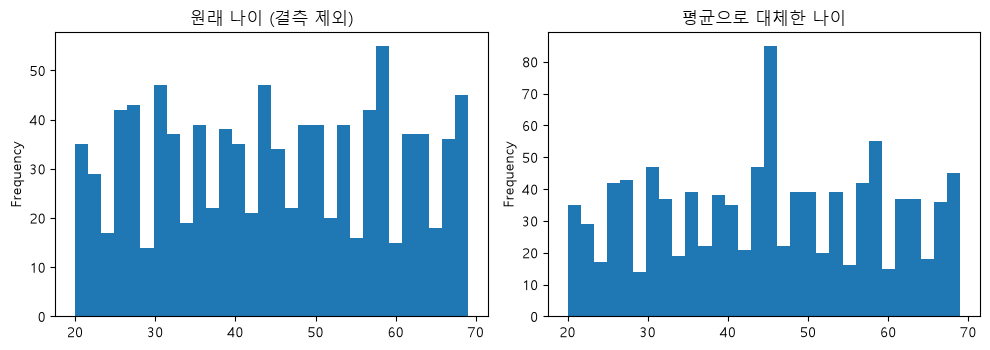

In [15]:
age_mean = df['customer_age'].fillna(df['customer_age'].mean())
print('평균:', round(age_mean.mean(), 3))
print('중앙값:', round(age_mean.median(), 3))
print('최빈값:', round(age_mean.mode()[0], 3))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
df['customer_age'].plot.hist(bins=30, ax=ax[0], title='원래 나이 (결측 제외)')
age_mean.plot.hist(bins=30, ax=ax[1], title='평균으로 대체한 나이')
plt.tight_layout()
plt.show()

In [16]:
print('나이 관측 수 / 전체 행:', df['customer_age'].count(), '/', len(df))
display(df.loc[df['delivery_date'].isnull(), ['status', 'delivery_date']])
before = len(df)
df = df.drop_duplicates().copy()
print('중복 제거:', before, '->', len(df))
duplicates_after_removal = int(df.duplicated().sum())
assert duplicates_after_removal == 0
assert before - len(df) == duplicates_before == 26
assert df.isnull().sum().equals(missing_before)

나이 관측 수 / 전체 행: 979 / 1030


,status,delivery_date
144,배송완료,NaT
311,배송완료,NaT
319,배송완료,NaT
560,배송완료,NaT
723,배송완료,NaT


중복 제거: 1030 -> 1004


## 실습 5: 이상치 검증과 수량 복원 (L8-1 29~31쪽 / L8-2 11~13쪽)


In [17]:
by_iqr = df['quantity'] > Q3 + 1.5 * IQR
by_rule = df['quantity'] > 100
print('IQR 규칙:', by_iqr.sum(), ' 업무 규칙:', by_rule.sum(), ' 같은 줄인가:', (by_iqr == by_rule).all())
assert (by_iqr == by_rule).all()
assert int(by_rule.sum()) == 22

IQR 규칙: 22  업무 규칙: 22  같은 줄인가: True


In [18]:
bad = by_rule
calc = df['quantity'] * df['unit_price']
diff = (df['total_sales'] - calc).abs()
print('22건 중 금액이 안 맞는 줄:', (diff[bad] > 1).sum())
print('불일치와 업무 규칙이 같은 줄인가:', ((diff > 1) == bad).all())
ratio = df['total_sales'] / df['unit_price']
display(ratio[bad].round(2).head(6))
assert ((diff > 1) == bad).all()
assert ((ratio[bad] - ratio[bad].round()).abs() < 1e-6).all()
assert ratio[bad].between(1, 100).all()

22건 중 금액이 안 맞는 줄: 22
불일치와 업무 규칙이 같은 줄인가: True


31     95.0
188    63.0
273    77.0
316    52.0
334    18.0
361    82.0
dtype: float64

수량 최대: 99  불일치: 0


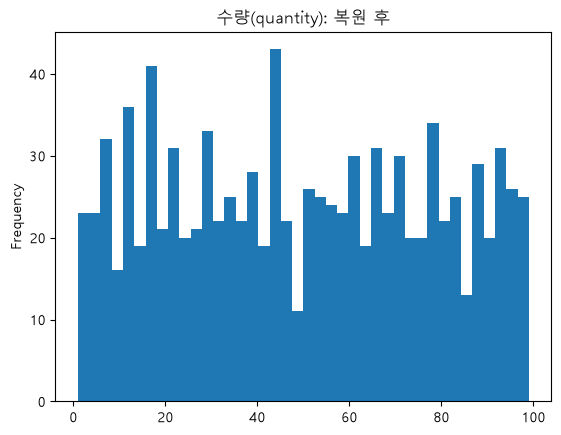

In [19]:
df.loc[bad, 'quantity'] = ratio[bad].round().astype(int)
calc = df['quantity'] * df['unit_price']
diff = (df['total_sales'] - calc).abs()
print('수량 최대:', df['quantity'].max(), ' 불일치:', (diff > 1).sum())
assert df['quantity'].max() == 99
assert (diff > 1).sum() == 0
df['quantity'].plot.hist(bins=40, title='수량(quantity): 복원 후')
plt.show()

## 날짜 오류 표시와 저장 (L8-1 32~33쪽 / L8-2 14~15쪽)


In [20]:
df['date_error'] = df['delivery_date'] < df['shipping_date']
display(df['date_error'].value_counts())
assert int(df['date_error'].sum()) == 147
assert df.shape == (1004, 15)
df.to_csv('sales_clean.csv', index=False)
print('정리된 크기:', df.shape)
print('sales_clean.csv 저장 완료 (원본은 보존)')
assert hashlib.sha256(source_file.read_bytes()).hexdigest() == source_sha256

date_error
False    857
True     147
Name: count, dtype: int64

정리된 크기: (1004, 15)
sales_clean.csv 저장 완료 (원본은 보존)


In [21]:
quality_summary = pd.DataFrame([
    ['결측 (나이 / 만족도 / 도착일)', '유지', '51 / 30 / 5', '51 / 30 / 5', '값을 만들거나 다른 정상 컬럼까지 제거하지 않음'],
    ['중복 행', '뒤쪽 제거', len(raw), len(df), '14개 칸의 값이 모두 동일'],
    ['금액 불일치', '수량을 금액 ÷ 단가로 복원', mismatch_before, int((diff > 1).sum()), '22건 모두 비율이 정수이며 업무 규칙 만족'],
    ['수량 > 150', '위와 같은 행을 복원', int((raw['quantity'] > 150).sum()), int((df['quantity'] > 150).sum()), '통계 규칙과 업무 규칙이 같은 행'],
    ['도착일 < 배송일', 'date_error 표시, 날짜 유지', reversed_before, int(df['date_error'].sum()), '어느 날짜가 틀렸는지 판단 불가'],
], columns=['점검', '처리', '전', '후', '근거'])
display(quality_summary)
display(pd.DataFrame({'원본 관측 수': raw[['customer_age', 'satisfaction', 'delivery_date']].count(), '정리 후 관측 수': df[['customer_age', 'satisfaction', 'delivery_date']].count()}))

,점검,처리,전,후,근거
0,결측 (나이 / 만족도 / 도착일),유지,51 / 30 / 5,51 / 30 / 5,값을 만들거나 다른 정상 컬럼까지 제거하지 않음
1,중복 행,뒤쪽 제거,1030,1004,14개 칸의 값이 모두 동일
2,금액 불일치,수량을 금액 ÷ 단가로 복원,22,0,22건 모두 비율이 정수이며 업무 규칙 만족
3,수량 > 150,위와 같은 행을 복원,22,0,통계 규칙과 업무 규칙이 같은 행
4,도착일 < 배송일,"date_error 표시, 날짜 유지",149,147,어느 날짜가 틀렸는지 판단 불가


,원본 관측 수,정리 후 관측 수
customer_age,979,953
satisfaction,1000,974
delivery_date,1025,999


## EDA: 정리한 데이터에게 질문하기 (L8-1 34~41쪽 / L8-2 16~23쪽)
### Q1. 보통 주문은 어떤 것인가?


In [22]:
stats = df[['quantity', 'unit_price', 'total_sales', 'customer_age']].agg(['mean', 'median', 'skew']).round(2)
stats

,quantity,unit_price,total_sales,customer_age
mean,49.41,250146.14,12413727.16,44.90
median,48.00,249449.48,9425457.90,45.00
skew,0.04,0.00,0.94,-0.02


### Q2. 무엇이 매출과 함께 움직이는가?


수량-총액 상관계수 고치기 전: 0.21  고친 뒤: 0.67


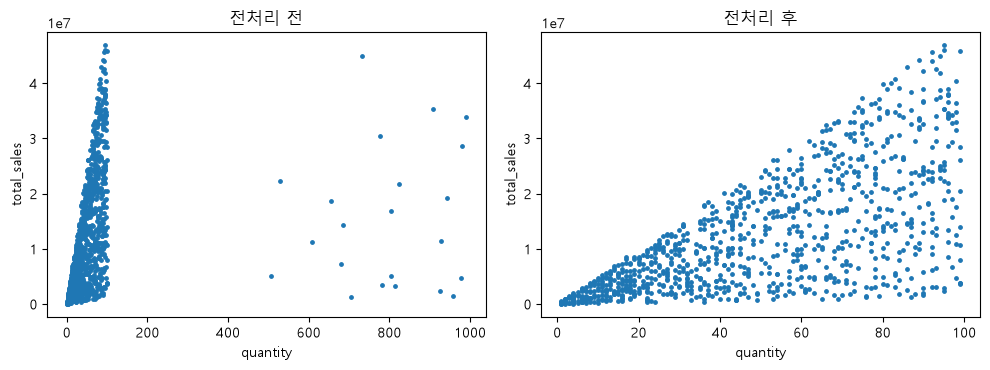

In [23]:
raw = pd.read_csv('sales_data.csv')
corr_before = raw['quantity'].corr(raw['total_sales'])
corr_after = df['quantity'].corr(df['total_sales'])
print('수량-총액 상관계수 고치기 전:', round(corr_before, 2), ' 고친 뒤:', round(corr_after, 2))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
raw.plot.scatter(x='quantity', y='total_sales', s=6, ax=ax[0], title='전처리 전')
df.plot.scatter(x='quantity', y='total_sales', s=6, ax=ax[1], title='전처리 후')
plt.tight_layout()
plt.show()

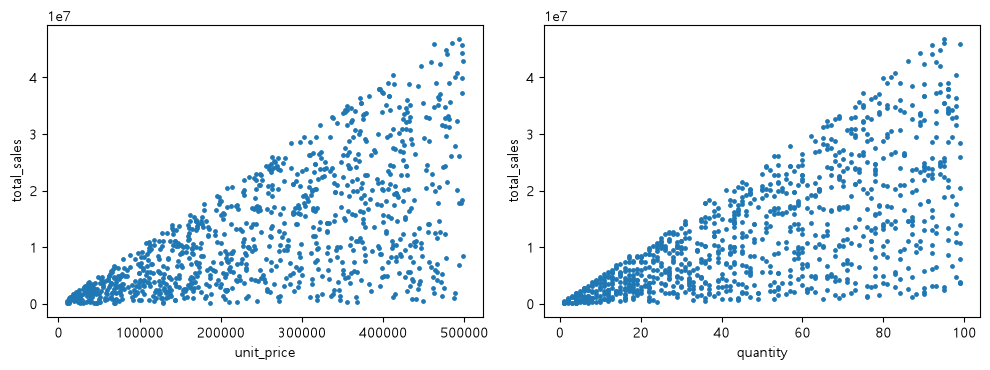

,quantity,unit_price,total_sales,customer_age,satisfaction
quantity,1.00,0.01,0.67,0.03,0.02
unit_price,0.01,1.00,0.65,-0.07,0.06
total_sales,0.67,0.65,1.00,-0.05,0.06
customer_age,0.03,-0.07,-0.05,1.00,-0.05
satisfaction,0.02,0.06,0.06,-0.05,1.00


In [24]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
df.plot.scatter(x='unit_price', y='total_sales', s=6, ax=ax[0])
df.plot.scatter(x='quantity', y='total_sales', s=6, ax=ax[1])
plt.tight_layout()
plt.show()
num = ['quantity', 'unit_price', 'total_sales', 'customer_age', 'satisfaction']
corr = df[num].corr()
corr.round(2)

In [25]:
pd.Series({col: len(df[[col, 'total_sales']].dropna()) for col in num if col != 'total_sales'}, name='매출 상관계수 계산 표본 수')

quantity        1004
unit_price      1004
customer_age     953
satisfaction     974
Name: 매출 상관계수 계산 표본 수, dtype: int64

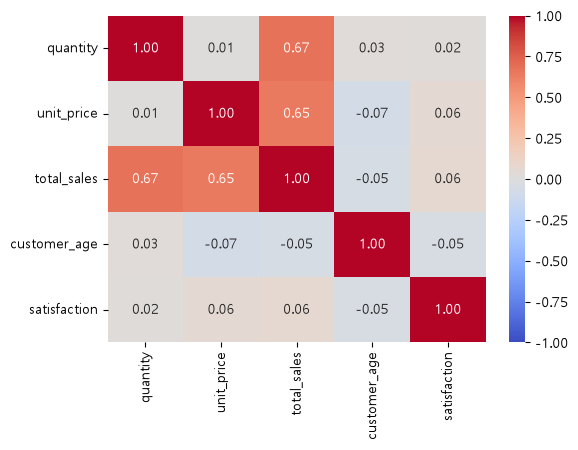

In [26]:
import seaborn as sns
plt.figure(figsize=(6, 4.6))
sns.heatmap(df[num].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.tight_layout()
plt.show()

### Q3. 카테고리·지역·달별 매출은 어떻게 다른가?


category
가구      28.4
도서      24.5
식품      25.1
의류      21.8
전자제품    24.7
Name: 카테고리 매출(억 원), dtype: float64

region
광주    26.0
대구    27.5
부산    26.6
서울    23.0
인천    21.6
Name: 지역 매출(억 원), dtype: float64

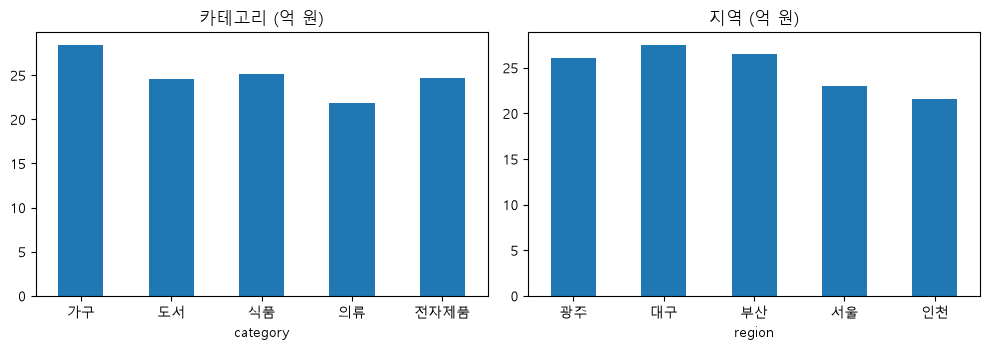

In [27]:
by_cat = df.groupby('category')['total_sales'].sum()
by_reg = df.groupby('region')['total_sales'].sum()
display((by_cat / 1e8).round(1).rename('카테고리 매출(억 원)'))
display((by_reg / 1e8).round(1).rename('지역 매출(억 원)'))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
(by_cat / 1e8).plot.bar(ax=ax[0], title='카테고리 (억 원)', rot=0)
(by_reg / 1e8).plot.bar(ax=ax[1], title='지역 (억 원)', rot=0)
plt.tight_layout()
plt.show()

In [28]:
pv = df.pivot_table(index='region', columns='category', values='total_sales', aggfunc='sum')
(pv / 1e8).round(1)

category,가구,도서,식품,의류,전자제품
region,,,,,
광주,5.1,3.4,5.0,5.4,7.1
대구,7.2,5.0,5.8,4.8,4.7
부산,6.6,5.4,6.8,3.6,4.1
서울,4.4,6.3,3.8,4.2,4.3
인천,5.2,4.3,3.8,3.9,4.4


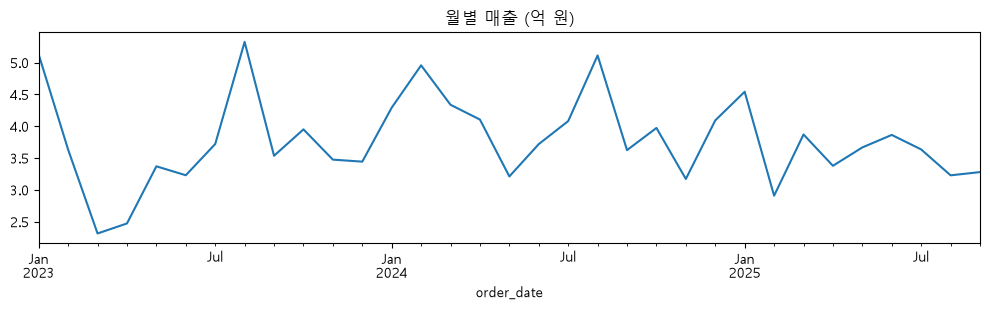

(Period('2023-08', 'M'), np.float64(5.3))

In [29]:
month = df['order_date'].dt.to_period('M')
monthly = df.groupby(month)['total_sales'].sum() / 1e8
monthly.plot(figsize=(10, 3.2), title='월별 매출 (억 원)')
plt.tight_layout()
plt.show()
monthly.idxmax(), round(monthly.max(), 1)

In [30]:
peak_region, peak_category = pv.stack().idxmax()
display(Markdown(
    f'### 분석 결과 정리\n'
    f'- **Q1:** 보통 주문의 중앙값은 수량 {df.quantity.median():.0f}개, 매출 {df.total_sales.median()/1e4:,.0f}만 원입니다.\n'
    f'- **Q2:** 매출과 수량의 상관계수는 {corr.loc["quantity", "total_sales"]:.2f}, 단가는 {corr.loc["unit_price", "total_sales"]:.2f}입니다. '
    f'나이는 {corr.loc["customer_age", "total_sales"]:.2f}, 만족도는 {corr.loc["satisfaction", "total_sales"]:.2f}입니다.\n'
    f'- **Q3:** 카테고리 합계는 {by_cat.idxmax()} {by_cat.max()/1e8:.1f}억 원부터 {by_cat.idxmin()} {by_cat.min()/1e8:.1f}억 원까지입니다. '
    f'지역×카테고리 최대는 {peak_region} {peak_category} {pv.stack().max()/1e8:.1f}억 원, 최대 월은 {monthly.idxmax()} {monthly.max():.1f}억 원입니다.\n'
    '- 반품 이유·광고 효과는 관련 컬럼이 없어 판단하지 않습니다. 미래 매출 예측, 머신러닝, HW5 과제는 이번 범위에 포함하지 않습니다.'
))

### 분석 결과 정리
- **Q1:** 보통 주문의 중앙값은 수량 48개, 매출 943만 원입니다.
- **Q2:** 매출과 수량의 상관계수는 0.67, 단가는 0.65입니다. 나이는 -0.05, 만족도는 0.06입니다.
- **Q3:** 카테고리 합계는 가구 28.4억 원부터 의류 21.8억 원까지입니다. 지역×카테고리 최대는 대구 가구 7.2억 원, 최대 월은 2023-08 5.3억 원입니다.
- 반품 이유·광고 효과는 관련 컬럼이 없어 판단하지 않습니다. 미래 매출 예측, 머신러닝, HW5 과제는 이번 범위에 포함하지 않습니다.

## 실행 결과 확인 (L8-1 42쪽 / L8-2 24쪽)


In [31]:
saved = pd.read_csv('sales_clean.csv')
assert saved.shape == (1004, 15)
assert duplicates_after_removal == 0
assert int(saved.duplicated().sum()) == int(df.duplicated().sum()) == 1
assert int(saved['date_error'].sum()) == 147
assert saved['quantity'].max() == 99
assert ((saved['total_sales'] - saved['quantity'] * saved['unit_price']).abs() > 1).sum() == 0
assert saved.isnull().sum().drop('date_error').equals(missing_before)
assert round(corr_before, 2) == 0.21 and round(corr_after, 2) == 0.67
assert hashlib.sha256(source_file.read_bytes()).hexdigest() == source_sha256
print('PASS: 원본 보존, 원본 중복 26행 제거, 1004행/15열, 금액 불일치 0, 수량 최대 99, 날짜 역전 표시 147, 결측 유지')
print('수량 복원 뒤 새로 동일해진 행:', saved.duplicated().sum())

PASS: 원본 보존, 원본 중복 26행 제거, 1004행/15열, 금액 불일치 0, 수량 최대 99, 날짜 역전 표시 147, 결측 유지
수량 복원 뒤 새로 동일해진 행: 1
